## 单斜相ZrO2 不同参数优化方法 5个轨道

In [1]:
import numpy as np
import mindspore as ms
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer
import matplotlib.pyplot as plt


from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

import numpy as np
import mindspore as ms
from mindquantum import *
import matplotlib.pyplot as plt
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer

In [2]:
from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

from openfermion.transforms import get_fermion_operator, jordan_wigner
from openfermion.linalg import get_ground_state, get_sparse_operator
import numpy
import scipy
import scipy.linalg

from mindquantum.algorithm.nisq import Transform
from mindquantum.algorithm.nisq import get_qubit_hamiltonian
from mindquantum.algorithm.nisq import uccsd_singlet_generator, uccsd_singlet_get_packed_amplitudes
from mindquantum.core.operators import TimeEvolution, count_qubits
from mindquantum.framework import MQAnsatzOnlyLayer


import itertools
from collections import OrderedDict

import numpy as np

from mindquantum.core.circuit import Circuit, decompose_single_term_time_evolution
from mindquantum.core.operators import FermionOperator, down_index, up_index
from mindquantum.third_party.interaction_operator import InteractionOperator
from mindquantum.utils.type_value_check import _require_package

from mindquantum.algorithm.nisq.chem.transform import Transform
from mindquantum.algorithm.nisq.chem.uccsd import _transform2pauli, _pauli2circuit

import random
import matplotlib.pyplot as plt

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")

[WARNING] ME(1078536:128217611612160,MainProcess):2025-06-12-09:39:21.530.000 [mindspore/context.py:1335] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [3]:
def _para_uccsd_singlet_generator(mol, threshold=0, n_qubits=0, n_electrons=0):  # pylint: disable=too-many-locals,too-many-statements
    """
    Generate a uccsd quantum circuit.

    Args:
        mol (molecular): A hdf5 molecular file generated by HiQ Fermion.
        threshold (float, optional): A threshold of parameters. If the absolute value of parameter is
            lower than the threshold, than we will not update it in VQE
            algorithm. Default: ``0``.
    """
    if n_qubits == 0:
        n_qubits = mol.n_qubits
        n_electrons = mol.n_electrons
    params = {}
    if n_qubits % 2 != 0:
        raise ValueError('The total number of spin-orbitals should be even.')
    out = []
    out_tmp = []
    n_spatial_orbitals = n_qubits // 2
    n_occupied = int(np.ceil(n_electrons / 2))
    n_virtual = n_spatial_orbitals - n_occupied

    # Unpack amplitudes
    n_single_amplitudes = n_occupied * n_virtual
    # Generate excitations
    spin_index_functions = [up_index, down_index]
    # Generate all spin-conserving single and double excitations derived
    # from one spatial occupied-virtual pair
    for i, (p, q) in enumerate(itertools.product(range(n_virtual), range(n_occupied))):  # pylint: disable=invalid-name
        # Get indices of spatial orbitals
        virtual_spatial = n_occupied + p
        occupied_spatial = q
        virtual_up = virtual_spatial * 2
        occupied_up = occupied_spatial * 2
        virtual_down = virtual_spatial * 2 + 1
        occupied_down = occupied_spatial * 2 + 1
        single_amps = mol.ccsd_single_amps[virtual_up, occupied_up]
        double1_amps = mol.ccsd_double_amps[virtual_up, occupied_up, virtual_down, occupied_down]
        single_amps_name = 'p' + str(i)
        double1_amps_name = 'p' + str(i + n_single_amplitudes)

        for spin in range(2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            this_index = spin_index_functions[spin]
            other_index = spin_index_functions[1 - spin]

            # Get indices of spin orbitals
            virtual_this = this_index(virtual_spatial)
            virtual_other = other_index(virtual_spatial)
            occupied_this = this_index(occupied_spatial)
            occupied_other = other_index(occupied_spatial)

            # Generate single excitations
            if abs(single_amps) > threshold:
                params[single_amps_name] = single_amps
                fermion_ops1 = FermionOperator(((occupied_this, 1), (virtual_this, 0)), 1)
                fermion_ops2 = FermionOperator(((virtual_this, 1), (occupied_this, 0)), 1)
                out.append([fermion_ops1 - fermion_ops2, single_amps_name])

            # Generate double excitation
            if abs(double1_amps) > threshold:
                params[double1_amps_name] = double1_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_this, 1), (occupied_this, 0), (virtual_other, 1), (occupied_other, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_other, 1), (virtual_other, 0), (occupied_this, 1), (virtual_this, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double1_amps_name])
    out.extend(out_tmp)
    out_tmp = []
    # Generate all spin-conserving double excitations derived
    # from two spatial occupied-virtual pairs
    for i, ((p, q), (r, s)) in enumerate(  # pylint: disable=invalid-name
        itertools.combinations(itertools.product(range(n_virtual), range(n_occupied)), 2)
    ):

        # Get indices of spatial orbitals
        virtual_spatial_1 = n_occupied + p
        occupied_spatial_1 = q
        virtual_spatial_2 = n_occupied + r
        occupied_spatial_2 = s

        virtual_1_up = virtual_spatial_1 * 2
        occupied_1_up = occupied_spatial_1 * 2
        virtual_2_up = virtual_spatial_2 * 2 + 1
        occupied_2_up = occupied_spatial_2 * 2 + 1

        double2_amps = mol.ccsd_double_amps[virtual_1_up, occupied_1_up, virtual_2_up, occupied_2_up]
        double2_amps_name = 'p' + str(i + 2 * n_single_amplitudes)

        # Generate double excitations
        for (spin_a, spin_b) in itertools.product(range(2), repeat=2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            index_a = spin_index_functions[spin_a]
            index_b = spin_index_functions[spin_b]

            # Get indices of spin orbitals
            virtual_1_a = index_a(virtual_spatial_1)
            occupied_1_a = index_a(occupied_spatial_1)
            virtual_2_b = index_b(virtual_spatial_2)
            occupied_2_b = index_b(occupied_spatial_2)
            if abs(double2_amps) > threshold:
                params[double2_amps_name] = double2_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_1_a, 1), (occupied_1_a, 0), (virtual_2_b, 1), (occupied_2_b, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_2_b, 1), (virtual_2_b, 0), (occupied_1_a, 1), (virtual_1_a, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double2_amps_name])
    return out, params

def generate_uccsd(molecular, threshold=-1, active_space_start=None, active_space_stop=None):
    """
    Generate a uccsd quantum circuit based on a molecular data generated by Openfermion.

    Args:
        molecular (Union[str, MolecularData]): the name of the molecular data file,
            or openfermion MolecularData.
        threshold (float): the threshold to filter out the uccsd amplitude. We only keep the
            excitation operator with absolute value of amplitude greater than `threshold`, so
            that if `threshold=0`, we only keep excitation operator with non zero amplitude. Default: ``0``.

    Returns:
        - **uccsd_circuit** (Circuit), the ansatz circuit generated by uccsd method.
        - **initial_amplitudes** (numpy.ndarray), the initial parameter values of uccsd circuit.
        - **parameters_name** (list[str]), the name of initial parameters.
        - **qubit_hamiltonian** (QubitOperator), the hamiltonian of the molecule.
        - **n_qubits** (int), the number of qubits in simulation.
        - **n_electrons** (int), the number of electrons of the molecule.
    """
    try:
        # pylint: disable=import-outside-toplevel
        from openfermion.chem import MolecularData
    except (ImportError, AttributeError):
        _require_package("openfermion", "1.5.0")
    if isinstance(molecular, str):
        mol = MolecularData(filename=molecular)
        mol.load()
    else:
        mol = molecular
    fermion_ansatz, parameters = _para_uccsd_singlet_generator(mol, threshold, n_qubits=2*(active_space_stop-active_space_start), n_electrons=mol.n_electrons-2*active_space_start)
    pauli_ansatz = _transform2pauli(fermion_ansatz)
    uccsd_circuit = _pauli2circuit(pauli_ansatz)
    ham_of = mol.get_molecular_hamiltonian(list(range(active_space_start)), active_indices=range(active_space_start, active_space_stop))
    inter_ops = InteractionOperator(*ham_of.n_body_tensors.values())
    ham_hiq = FermionOperator(inter_ops)
    qubit_hamiltonian = Transform(ham_hiq).jordan_wigner()
    qubit_hamiltonian = qubit_hamiltonian.compress()

    parameters_name = list(parameters.keys())
    initial_amplitudes = [parameters[i] for i in parameters_name]
    return uccsd_circuit, initial_amplitudes, parameters_name, qubit_hamiltonian, 2*(active_space_stop-active_space_start), mol.n_electrons-2*active_space_start

In [4]:
def get_mol(phase=1):
    # 根据输入phase选择不同的晶体结构
    if phase == 1:
        # ① 单斜相ZrO2
        a = 5.15  # Å
        b = 5.23  # Å
        c = 5.33  # Å
        beta = 99.44 * np.pi / 180  # 弧度
        # 晶胞向量
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([c * np.cos(beta), 0, c * np.sin(beta)])
        # 原子分数坐标和元素
        atoms = [
            ('Zr', [0.276309, 0.042147, 0.209598]),
            ('O',  [0.930791, 0.833712, 0.156172]),
            ('O',  [0.449303, 0.742580, 0.978604])
        ]
        description = "Monoclinic ZrO2"
    elif phase == 2:
        # ② 四方相ZrO2
        a = b = 3.60  # Å
        c = 5.23      # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [0, 0.5, 0.301775])
        ]
        description = "Tetragonal ZrO2"
    elif phase == 3:
        # ③ 六方相ZrO
        a = 5.31  # Å
        c = 3.2   # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([-a/2, a*np.sqrt(3)/2, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [1/3, 2/3, 0.25])
        ]
        description = "Hexagonal ZrO"
    else:
        raise ValueError("Invalid phase. Choose 1, 2, or 3.")

    # 将分数坐标转换为笛卡尔坐标
    geometry = []
    for element, frac_coords in atoms:
        # 分数坐标转换为笛卡尔坐标
        cart_coords = (
            frac_coords[0] * a_vec +
            frac_coords[1] * b_vec +
            frac_coords[2] * c_vec
        )
        geometry.append([element, list(cart_coords)])
    print(geometry)

    # 设置基组和自旋多重性
    basis = 'gth-dzvp-molopt-sr'
    multiplicity = 1  # 假设为闭壳层单重态

    # 创建分子对象
    molecule = MolecularData(
        geometry,
        basis,
        multiplicity,
        description=description
    )

    # molecule = run_pyscf(
    #     molecule,
    #     run_scf=1,
    #     run_ccsd=1,
    #     #run_fci=1
    # )

    # 显式指定文件名
    #molecule.filename = "./test_h2.hdf5"
    # molecule.save()
    # molecule_file = molecule.filename
    # print(molecule_file.split('/')[-1])

    # 运行或加载计算
    try:
        molecule.load()
    except:
        molecule = run_pyscf(
            molecule,
            run_scf=1,
            run_ccsd=1,
        )
        molecule.save()
        molecule.load()
        molecule_file = molecule.filename
        print(molecule_file.split('/')[-1])

    # 打印能量信息
    print(f'{description} - Hartree-Fock energy: {molecule.hf_energy} Hartree.')
    print(f'{description} - CCSD energy: {molecule.ccsd_energy} Hartree.')
   # print(f'{description} - FCI energy: {molecule.fic_energy} Hartree.')

    
    return molecule

## 单斜相ZrO2

In [5]:
ZrO2d=get_mol(1)

[['Zr', [1.2397611467218508, 0.22042881, 1.102028681533527]], ['O', [4.657048362037544, 4.36031376, 0.8211243583071115]], ['O', [1.4584165528787967, 3.8836934000000003, 5.145324267709785]]]
Monoclinic ZrO2 - Hartree-Fock energy: -608.1196082141597 Hartree.
Monoclinic ZrO2 - CCSD energy: -608.3663660904948 Hartree.


## 5轨道 UCCSD ansatz

## LSTM优化

In [35]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=26, active_space_stop=31)

In [36]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
ham = Hamiltonian(hamiltonian_QubitOp)      # 生成哈密顿量
#init_state_circ = UN(H, g_6.nodes)         # 生成均匀叠加态，即对所有量子比特作用H门
ansatz = ansatz_circuit   # 生成拟设线路
circ = hartreefock_wfn_circuit + ansatz_circuit.as_encoder()       # 将初始化线路与拟设线路组合成总的线路
circ.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                            
╭───────────────────────┬────────────────────────────────────────────╮
│ Info                  │ value                                      │
├───────────────────────┼────────────────────────────────────────────┤
│ Number of qubit       │ 10                                         │
├───────────────────────┼────────────────────────────────────────────┤
│ Total number of gate  │ 6588                                       │
│ Barrier               │ 1440                                       │
│ Noise Channel         │ 0                                          │
│ Measurement           │ 0                                          │
├───────────────────────┼────────────────────────────────────────────┤
│ Parameter gate        │ 360                                        │
│ 27 encoder parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰───────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [37]:
# 采用一个 LSTM 作为对量子线路参数的经典优化器
# LSTM 输入为量子线路旧的参数，输出作为量子线路新的参数。
class TrainableLSTM(nn.Cell):
    def __init__(self):
        super(TrainableLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size=len(circ.params_name),
                                            hidden_size=len(circ.params_name),
                                            num_layers=1,
                                            has_bias=True,
                                            batch_first=False,
                                            bidirectional=False)
        self.hidden_size = self.lstm.hidden_size
        self.batch_size = 1
        self.num_layers = 1
        self.hx = (Parameter(initializer( 'normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='h'),
                         Parameter(initializer('normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='c'))

    def construct(self, x):
        _, (x, _) = self.lstm(x, self.hx)
        return x

In [38]:
# LSTM 层的损失函数为量子线路最终的期望值。
class All_Net(nn.Cell):
    def __init__(self, grad_ops, init_paras):
        super(All_Net, self).__init__()
        self.lstm = TrainableLSTM()
        self.qnn_ops = MQEncoderOnlyOps(grad_ops) # 量子线路的参数不直接参与训练
        self.init_paras = init_paras
        self.squeeze = ms.ops.Squeeze(0)

    def construct(self):  # x 为量子线路旧的网络参数， out 为量子线路新的参数
        self.init_paras = self.lstm(self.init_paras)
        x = self.squeeze(self.init_paras)
        out = self.qnn_ops(x)
        return out

In [39]:
sim = Simulator('mqvector', circ.n_qubits) # 创建模拟器
grad_ops = sim.get_expectation_with_grad(ham, circ)

In [40]:

paras = Tensor(np.random.random([1, 1, len(circ.params_name)]).astype(np.float32))  # 量子线路初始参数
all_net = All_Net(grad_ops, paras)
opt = nn.Adam(all_net.trainable_params(),  learning_rate=0.1)  # 对 LSTM 层的参数，采用 Adam 进行优化
train_net = nn.TrainOneStepCell(all_net, opt)
train_net.set_train()

TrainOneStepCell<
  (network): All_Net<
    (lstm): TrainableLSTM<
      (lstm): LSTM<
        (rnn): _DynamicLSTMCPUGPU<>
        (dropout_op): Dropout<p=0.0>
        >
      >
    (qnn_ops): MQEncoderOnlyOps<10 qubits mqvector VQA Operator>
    >
  (optimizer): Adam<>
  (grad_reducer): Identity<>
  >

In [41]:
# 训练过程
energy_data = []
steps = 100
for step in range(steps):
    energy = train_net()
    energy_data.append(energy.asnumpy()[0, 0])
    if step % 10 == 0:
        print(f"Step {step}: Energy = {energy[0, 0]}")

Step 0: Energy = -607.5295
Step 10: Energy = -608.1056
Step 20: Energy = -608.11786
Step 30: Energy = -608.1193
Step 40: Energy = -608.11945
Step 50: Energy = -608.11957
Step 60: Energy = -608.11957
Step 70: Energy = -608.1196
Step 80: Energy = -608.1196
Step 90: Energy = -608.1197


/tmp/ipykernel_1078536/898229535.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


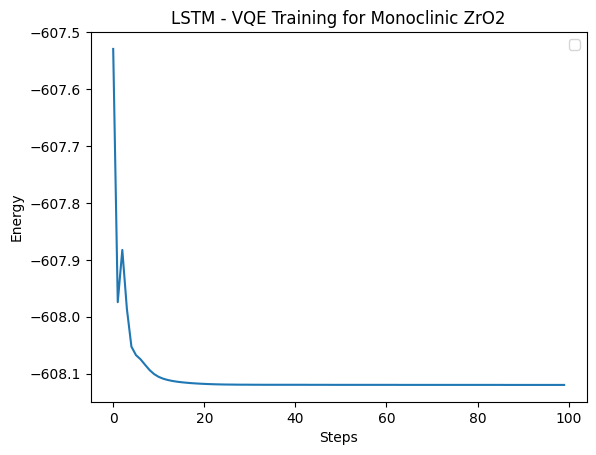

Estimated ground state energy of Monoclinic ZrO2: -608.1196899414062


In [42]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_data)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_data[-1]}")

In [18]:
-608.1195678710938

-608.1195678710938

In [43]:
print('L5_LSTM=',energy_data)

L5_LSTM= [-607.5295, -607.97437, -607.8825, -607.98566, -608.0524, -608.0673, -608.07465, -608.08435, -608.0937, -608.10077, -608.1056, -608.1088, -608.1111, -608.11273, -608.114, -608.115, -608.1158, -608.11646, -608.117, -608.1175, -608.11786, -608.1182, -608.11847, -608.1187, -608.1189, -608.119, -608.1191, -608.1192, -608.11926, -608.11926, -608.1193, -608.1194, -608.1194, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1197, -

## bfgs 优化

In [44]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=26, active_space_stop=31)

In [45]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [46]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [29]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [30]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -607.1925575347118
Step: 10,	energy: -607.4453272537578
Step: 15,	energy: -607.6508660726228
Step: 20,	energy: -608.0655579067259
Step: 25,	energy: -608.1083369445165
Step: 30,	energy: -608.119061986851
Step: 35,	energy: -608.119585708706
Step: 40,	energy: -608.1196008625731
Step: 45,	energy: -608.1196080792743
Step: 50,	energy: -608.1196084321311


/tmp/ipykernel_1078536/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


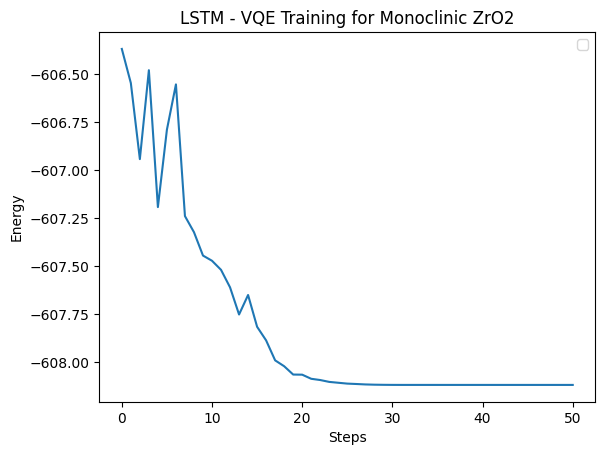

Estimated ground state energy of Monoclinic ZrO2: -608.1196084324918


In [31]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [32]:
-608.1196084324918

-608.1196084324918

In [34]:
print('L5_bfgs=',energy_list)

L5_bfgs= [-606.3680708826728, -606.5460214558203, -606.9425001814066, -606.4789827519373, -607.1925575347118, -606.789051515834, -606.5530540030348, -607.2395825793161, -607.3233935078852, -607.4453272537578, -607.4723680943312, -607.519679938099, -607.6109574369093, -607.7525233982471, -607.6508660726228, -607.8165020242201, -607.887499780741, -607.9915492855582, -608.0221632724254, -608.0655579067259, -608.0661905871051, -608.0876275905298, -608.0941272716238, -608.1038742392616, -608.1083369445165, -608.1127718993904, -608.1148190131211, -608.1170697234804, -608.1183718054199, -608.119061986851, -608.1194271796454, -608.1195662297802, -608.1195800267624, -608.1195820778304, -608.119585708706, -608.1195916991201, -608.1195982439216, -608.1195994758117, -608.1196003253895, -608.1196008625731, -608.119601782247, -608.1196033160775, -608.1196055980034, -608.119607314985, -608.1196080792743, -608.1196082863007, -608.1196083528312, -608.119608402598, -608.119608426968, -608.1196084321311,

## 优化

In [47]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=26, active_space_stop=31)

In [48]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [49]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [74]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [75]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='L-BFGS-B', jac=True)

Step: 5,	energy: -606.0134696217481
Step: 10,	energy: -607.4399786086902
Step: 15,	energy: -607.4976109902487
Step: 20,	energy: -607.548674731134
Step: 25,	energy: -607.5427192777876
Step: 30,	energy: -607.9135924853107
Step: 35,	energy: -608.0132119814715
Step: 40,	energy: -608.1175541479623
Step: 45,	energy: -608.119563711206
Step: 50,	energy: -608.1196073323911


/tmp/ipykernel_1078536/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


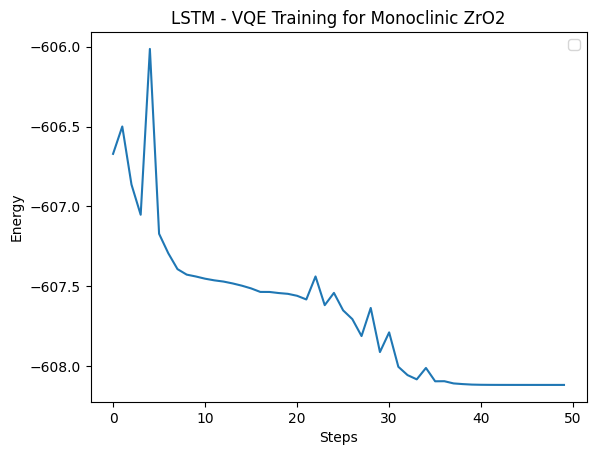

Estimated ground state energy of Monoclinic ZrO2: -608.1196073323911


In [76]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [61]:
-608.1116033025577

-608.1116033025577

In [77]:
print('L5_L-BFGS-B=',energy_list)

L5_L-BFGS-B= [-606.6712849868186, -606.4997012864509, -606.8634635313376, -607.0530662271909, -606.0134696217481, -607.1721561917645, -607.2942328875251, -607.3937389729755, -607.4282256787099, -607.4399786086902, -607.4537666824405, -607.4640745158931, -607.4717336401931, -607.4835122017802, -607.4976109902487, -607.514622413667, -607.5366425350293, -607.5368711483045, -607.5436973811005, -607.548674731134, -607.5609244855666, -607.5838506031292, -607.4397221293596, -607.6196358659721, -607.5427192777876, -607.6522361735351, -607.7070601519458, -607.8133174864128, -607.6371259294717, -607.9135924853107, -607.7901995204819, -608.0059079987052, -608.0580266357813, -608.0847068915454, -608.0132119814715, -608.0968525403366, -608.0963354071437, -608.1101900198712, -608.1144004962777, -608.1175541479623, -608.1187869339236, -608.1192429357498, -608.1194459203299, -608.1195193646655, -608.119563711206, -608.1195944834503, -608.119604953533, -608.1196067606494, -608.1196065438658, -608.11960

## youhua

In [78]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=26, active_space_stop=31)

In [79]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [80]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [88]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [89]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='CG', jac=True)

Step: 5,	energy: -606.6217095828628
Step: 10,	energy: -607.1416057285869
Step: 15,	energy: -607.8759499033512
Step: 20,	energy: -608.0975822058084
Step: 25,	energy: -608.1113822560641
Step: 30,	energy: -608.1177175998508
Step: 35,	energy: -608.1185064151163
Step: 40,	energy: -608.1188356030933
Step: 45,	energy: -608.1193584056728
Step: 50,	energy: -608.1194233567928
Step: 55,	energy: -608.119509350796
Step: 60,	energy: -608.1195371925763
Step: 65,	energy: -608.119566207363
Step: 70,	energy: -608.1195738002449
Step: 75,	energy: -608.1195976389624
Step: 80,	energy: -608.1196013937143
Step: 85,	energy: -608.1196023637077
Step: 90,	energy: -608.1196029947845
Step: 95,	energy: -608.1196057556696
Step: 100,	energy: -608.1196069235773
Step: 105,	energy: -608.1196069832257
Step: 110,	energy: -608.1196071280109
Step: 115,	energy: -608.1196072299666
Step: 120,	energy: -608.1196073584659
Step: 125,	energy: -608.1196075383193
Step: 130,	energy: -608.119607826219
Step: 135,	energy: -608.11960787394

/tmp/ipykernel_1078536/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


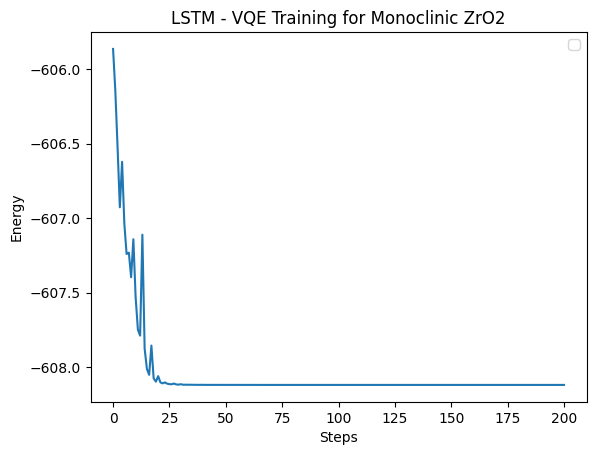

Estimated ground state energy of Monoclinic ZrO2: -608.1196083976554


In [90]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [84]:
-608.119576346244

-608.119576346244

In [91]:
print('L5_CG=',energy_list)

L5_CG= [-605.8637407717167, -606.1458145156461, -606.5263815364501, -606.9269640471161, -606.6217095828628, -607.038316831175, -607.2405514175446, -607.2314981303734, -607.3966888219666, -607.1416057285869, -607.5291144458487, -607.7472699157022, -607.7887401390982, -607.1111003003338, -607.8759499033512, -608.0114295869778, -608.0518366634167, -607.8553391504036, -608.0760074764909, -608.0975822058084, -608.0606827164141, -608.1028550883437, -608.1092592922447, -608.1026377901418, -608.1113822560641, -608.1143573888581, -608.1150904894761, -608.1104301870455, -608.1162280373134, -608.1177175998508, -608.1149396604015, -608.1181085672036, -608.1178601616008, -608.1182595824555, -608.1185064151163, -608.1186586013488, -608.1187611686325, -608.1188896684658, -608.1191900139031, -608.1188356030933, -608.1192848347174, -608.119299746995, -608.1193366629011, -608.1193153153038, -608.1193584056728, -608.11936950453, -608.1193730921277, -608.1193989168141, -608.1194297360194, -608.11942335679

## 优化

In [92]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=26, active_space_stop=31)

In [93]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [94]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [114]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [115]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='SLSQP', jac=True)

Step: 5,	energy: -607.1956164540807
Step: 10,	energy: -607.5235199002639
Step: 15,	energy: -606.5588577907965
Step: 20,	energy: -607.9760948486714
Step: 25,	energy: -607.9709094581896
Step: 30,	energy: -608.0969584434208
Step: 35,	energy: -608.1009267448222
Step: 40,	energy: -608.1015153582251
Step: 45,	energy: -608.1026048120112
Step: 50,	energy: -608.1056966302531
Step: 55,	energy: -608.1064011407909
Step: 60,	energy: -608.1071296692578
Step: 65,	energy: -608.1075701007967
Step: 70,	energy: -608.1078014838988
Step: 75,	energy: -608.1081260613427
Step: 80,	energy: -608.1090007652498
Step: 85,	energy: -608.1095664767461
Step: 90,	energy: -608.1097239000898
Step: 95,	energy: -608.1102447653903
Step: 100,	energy: -608.1103227007101
Step: 105,	energy: -608.1103534987618
Step: 110,	energy: -608.1103955776382
Step: 115,	energy: -608.1105652507489
Step: 120,	energy: -608.1106432220033


/tmp/ipykernel_1078536/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


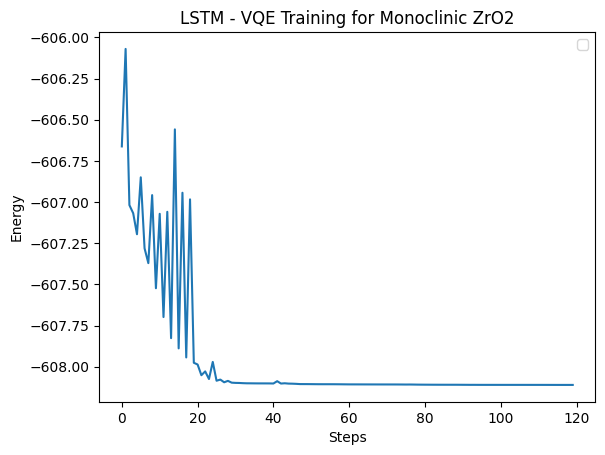

Estimated ground state energy of Monoclinic ZrO2: -608.1106432220033


In [116]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [107]:
-608.1106201537842

-608.1106201537842

In [108]:
print('L5_SLSQP=',energy_list)

L5_SLSQP= [-606.1998002019078, -606.4496625096635, -606.9010044205489, -606.4557775190029, -607.1534493706629, -606.902118692324, -607.3484014439088, -606.949885500273, -607.491781248725, -606.5429400258862, -607.5885287429046, -606.913612921495, -607.660248898531, -607.0238339408401, -607.7255931994289, -607.3823453521835, -607.8164633187271, -607.8122085872571, -607.9106976179232, -607.6240502320113, -607.9466292203059, -607.8809537656089, -607.9754596245432, -607.824988416087, -607.9949613197042, -607.8692588452534, -608.0185526002881, -608.012537628399, -608.0400149797898, -607.9986753206722, -608.0536104625729, -608.0314197389654, -608.0650878868456, -608.0742453831454, -608.024365494155, -608.0814133519414, -608.0642434744698, -608.0891231081371, -608.0810290462261, -608.0942158324483, -608.0945350492836, -608.096189145282, -608.0978345092211, -608.0977398147547, -608.0988904719455, -608.0994435392264, -608.0998369412766, -608.100090051766, -608.100378877966, -608.1010627299939, 

## 优化

In [205]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [206]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='BFGS', jac=True)

Step: 5,	energy: -606.5144978313549
Step: 10,	energy: -607.8308681371195
Step: 15,	energy: -608.1154789446484
Step: 20,	energy: -608.1187601805314
Step: 25,	energy: -608.1195885116482
Step: 30,	energy: -608.1196082801125
Step: 35,	energy: -608.1196083831946


/tmp/ipykernel_1078536/384419056.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


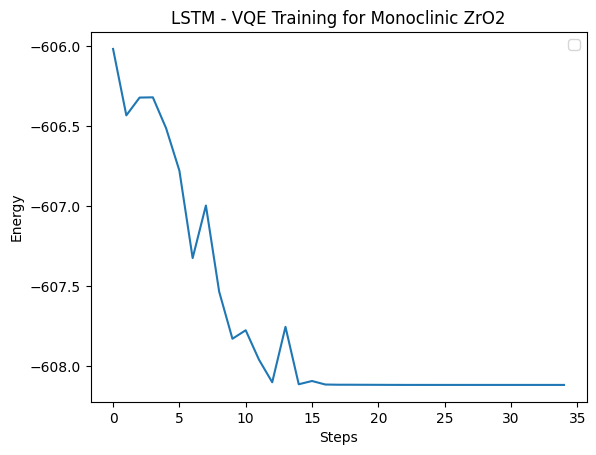

Estimated ground state energy of Monoclinic ZrO2: -608.1196083831946


In [207]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()


print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [208]:
print('L5_BFGS=',energy_list)

L5_BFGS= [-606.0180841114397, -606.4336834150342, -606.32235229004, -606.3208957819592, -606.5144978313549, -606.7793060265142, -607.3261391858771, -606.9975585251552, -607.5363355860457, -607.8308681371195, -607.7777433955346, -607.9614786744331, -608.1030023347422, -607.7563183455246, -608.1154789446484, -608.0950387657568, -608.1170251770199, -608.1184360083037, -608.1184534488089, -608.1187601805314, -608.1190495918655, -608.1193801425518, -608.1195550543459, -608.1195820478324, -608.1195885116482, -608.1195918713747, -608.1195971793106, -608.1196039023533, -608.1196076093804, -608.1196082801125, -608.1196083173918, -608.1196083296855, -608.1196083497515, -608.1196083749494, -608.1196083831946]
